# — Introduction to Supervised Machine Learning

**Learning objectives**

By the end of this lesson, you should be able to:
- Distinguish supervised classification from supervised regression.
- Identify features (`X`) and a target (`y`).
- Split data into training and test sets and explain why the split matters.
- Train a K-Nearest Neighbors (KNN) model and generate predictions.
- Interpret basic classification and regression metrics.
- Compare training and test performance as a first check for overfitting and underfitting.

**Today:** we will keep KNN hyperparameters fixed. We will study feature transformations and model tuning in later lessons.

## What is machine learning?

Machine learning uses patterns in data to make predictions or support decisions about new observations.

- **Supervised learning:** examples include known outcomes (targets). **Classification** predicts categories; **regression** predicts numbers.
- **Unsupervised learning:** looks for structure without a supplied target (e.g., groups or lower-dimensional representations).
- **Reinforcement learning:** an agent learns through actions and feedback from an environment.

In this notebook, we focus entirely on **supervised learning**.

| Question | Example | Task |
|---|---|---|
| Which species is this flower? | Iris | Classification |
| What is the median house value in this area? | California Housing | Regression |

**Check for understanding (1 minute)**  
Is predicting whether a passenger was transported during a spaceship journey classification or regression? What would the target represent?

## The supervised learning workflow

We will follow the same steps for classification and regression. **The test set is not used to fit the model.**

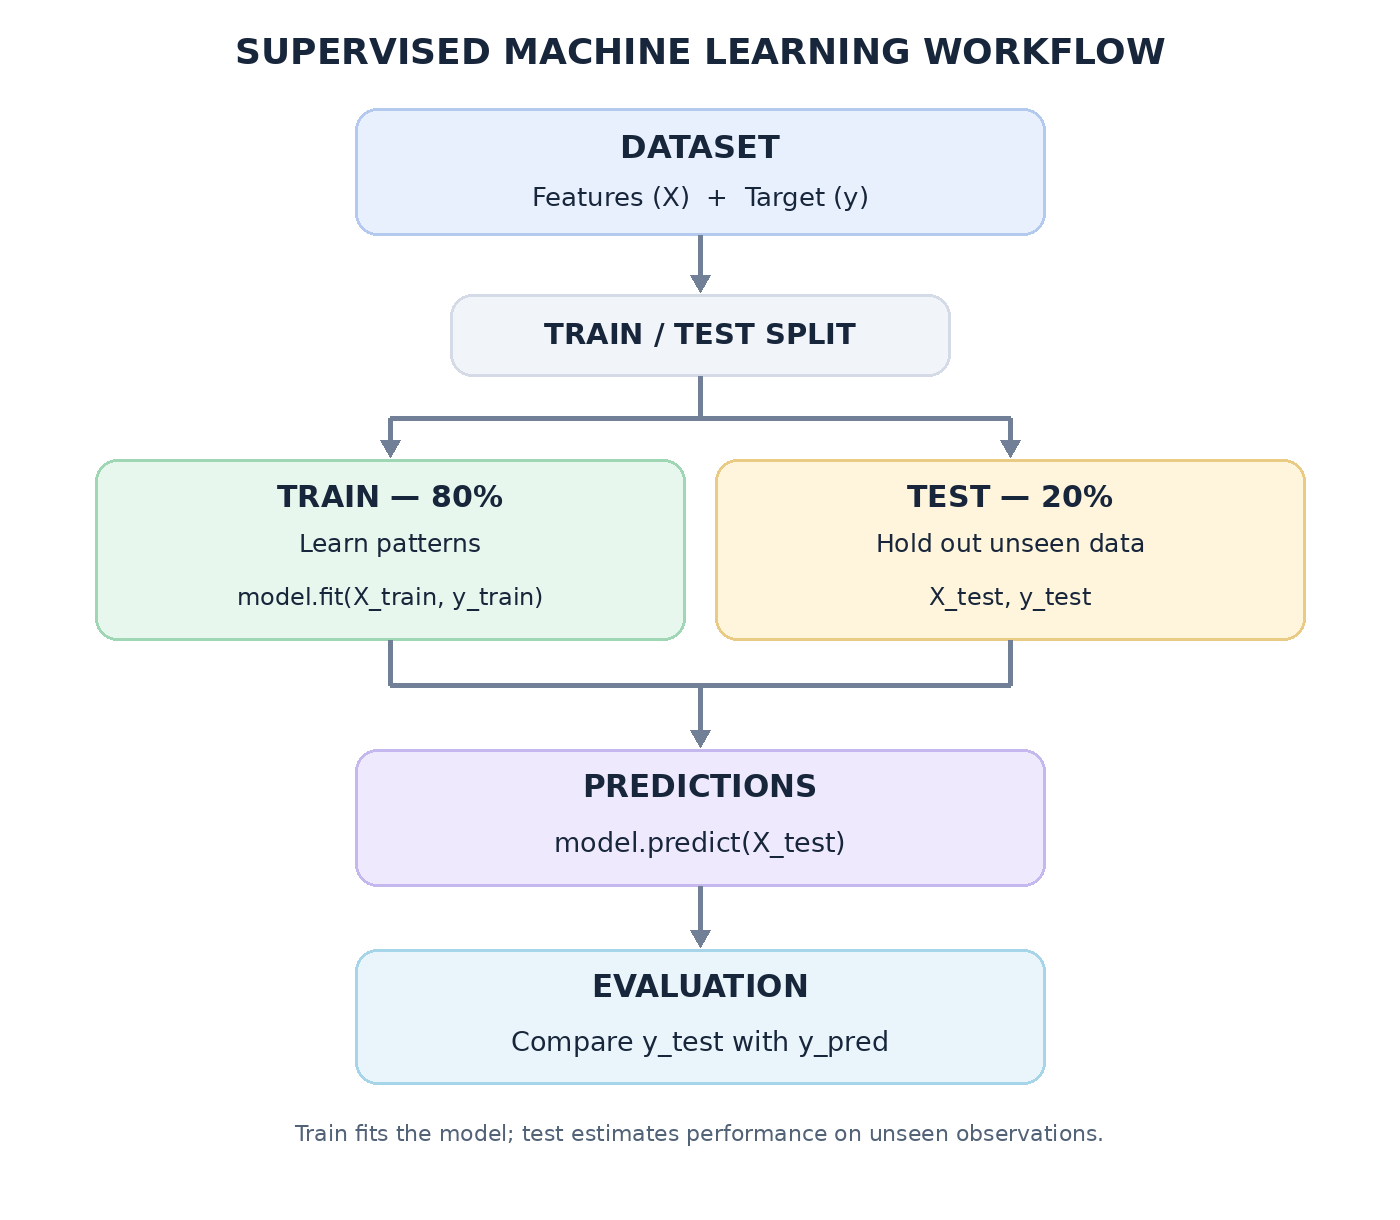

The **training set** is used to learn patterns; the **test set** is reserved to evaluate predictions on unseen observations.

## Classification — Iris flowers

Each row represents a flower. The **features** are four measurements of its sepals and petals. The **target** is one of three species.

We will use scikit-learn's built-in Iris dataset.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

sns.set_theme(style="whitegrid")

### Load and inspect the data (minimal EDA)

We only need enough EDA to understand what we are predicting and to identify obvious preparation issues. We will **not** repeat a full exploratory analysis.

In [ ]:
iris = load_iris(as_frame=True)

iris_df = iris.frame.copy()
print(f"Shape: {iris_df.shape}")
print("Missing values:", iris_df.isna().sum().sum())
display(iris_df.head())

# Check the class balance; this helps us interpret accuracy.
class_counts = iris_df["target"].value_counts().sort_index()
print("Class counts:")
print(pd.Series(class_counts.values, index=iris.target_names))

In [ ]:
# One quick visual check: can two measurements help distinguish species?
plot_df = iris_df.copy()
plot_df["species"] = plot_df["target"].map(dict(enumerate(iris.target_names)))

sns.scatterplot(
    data=plot_df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
)
plt.title("Iris: two features and three species")
plt.show()

**Think:** These two features appear useful, but our model will receive **all four** numerical measurements. Visual separation is suggestive, not proof of future predictive performance.

### Visualizing the feature–target split

We first split the dataset **by columns**. Each row remains aligned: the features and target on the same row describe the **same flower**.

<div style="max-width:760px;margin:16px auto;font-family:Arial,sans-serif">
  <div style="font-family:Arial,sans-serif;text-align:center;border-radius:10px;padding:12px 16px;background:#f1f5f9;border:2px solid #64748b;color:#334155;"><strong>Original Iris dataset</strong><div style="font-size:13px;margin-top:5px">150 observations · 4 feature columns + 1 target column</div></div>
  <div style="text-align:center;font-size:25px;color:#64748b;padding:5px">&#8595;</div>
  <div style="display:flex;gap:12px;align-items:stretch">
    <div style="flex:4;min-width:0;font-family:Arial,sans-serif;text-align:center;border-radius:10px;padding:12px 16px;background:#dbeafe;border:2px solid #2563eb;color:#1e3a8a;"><strong>X — Features</strong><div style="font-size:13px;margin-top:6px">Sepal length · Sepal width<br>Petal length · Petal width</div><div style="font-size:12px;margin-top:8px">150 rows × 4 columns</div></div>
    <div style="flex:2;min-width:0;font-family:Arial,sans-serif;text-align:center;border-radius:10px;padding:12px 16px;background:#fef3c7;border:2px solid #d97706;color:#78350f;"><strong>y — Target</strong><div style="font-size:13px;margin-top:6px">Species<br>(0, 1 or 2)</div><div style="font-size:12px;margin-top:8px">150 labels</div></div>
  </div>
  <div style="text-align:center;color:#475569;font-size:13px;margin-top:10px">Split columns, not observations: X[i] and y[i] still refer to the same flower.</div>
</div>


### Visualizing the train–test split

Next, we split **by rows**, applying the **same observation indices** to `X` and `y`. For Iris, `train_test_split(..., test_size=0.2, stratify=y_iris)` creates approximately an 80/20 split while preserving class proportions.

<div style="max-width:760px;margin:16px auto;font-family:Arial,sans-serif">
  <div style="display:flex;gap:12px">
    <div style="flex:4;min-width:0;font-family:Arial,sans-serif;text-align:center;border-radius:10px;padding:12px 16px;background:#dbeafe;border:2px solid #2563eb;color:#1e3a8a;"><strong>X — Features</strong><div style="font-size:13px">150 rows × 4 columns</div></div>
    <div style="flex:2;min-width:0;font-family:Arial,sans-serif;text-align:center;border-radius:10px;padding:12px 16px;background:#fef3c7;border:2px solid #d97706;color:#78350f;"><strong>y — Target</strong><div style="font-size:13px">150 labels</div></div>
  </div>
  <div style="text-align:center;font-size:25px;color:#64748b;padding:5px">&#8595;</div>
  <div style="display:flex;gap:12px;align-items:stretch">
    <div style="flex:4;min-width:0;font-family:Arial,sans-serif;text-align:center;border-radius:10px;padding:12px 16px;background:#dcfce7;border:2px solid #16a34a;color:#14532d;"><strong>Training set — 80%</strong><div style="font-size:13px;margin-top:6px">X_train: 120 × 4<br>y_train: 120 labels</div><div style="font-size:12px;margin-top:6px">Used to fit the model</div></div>
    <div style="flex:2;min-width:0;font-family:Arial,sans-serif;text-align:center;border-radius:10px;padding:12px 16px;background:#fef3c7;border:2px solid #d97706;color:#78350f;"><strong>Test set — 20%</strong><div style="font-size:13px;margin-top:6px">X_test: 30 × 4<br>y_test: 30 labels</div><div style="font-size:12px;margin-top:6px">Held out for evaluation</div></div>
  </div>
  <div style="text-align:center;color:#475569;font-size:13px;margin-top:10px">Both X and y are split using identical row indices; training and test observations do not overlap.</div>
</div>


### Define `X` and `y`, then split the data

- `X` contains the predictor columns.
- `y` contains the labels we want to predict.
- `stratify=y` keeps class proportions approximately similar across the two sets; this is especially useful for classification.
- `random_state` makes the split reproducible.

The 80/20 proportion is a practical choice for today's example, not a universal rule.

**Important:** Classification depends on what the target **means**, not on its data type. Species may be stored as `0`, `1`, `2`, but they are categories, not quantities. A binary `0`/`1` target can also be classification.


In [ ]:
X_iris = iris_df.drop(columns="target")
y_iris = iris_df["target"]

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.20,
    random_state=0,
    stratify=y_iris,
)

print("Training observations:", len(X_train_iris))
print("Test observations:", len(X_test_iris))
print("Training features:", list(X_train_iris.columns))

**Check for understanding (1 minute)**  
If we accidentally include the target among the features, what might happen to our evaluation on new observations?

### Train KNN and predict

KNN classifies a new observation using the labels of its nearest training observations. **Distance matters**, which is why feature scaling will become important in Tuesday's lesson.

For now, we choose **`n_neighbors=3` before looking at test performance**. We will not tune it today.

In [ ]:
knn_classifier = KNeighborsClassifier(n_neighbors=3)
knn_classifier.fit(X_train_iris, y_train_iris)

y_pred_test_knn = knn_classifier.predict(X_test_iris)

comparison_iris = pd.DataFrame({
    "actual_species": y_test_iris.map(dict(enumerate(iris.target_names))),
    "predicted_species": pd.Series(y_pred_test_knn, index=y_test_iris.index).map(
        dict(enumerate(iris.target_names))
    ),
})
display(comparison_iris.head(10))

### Evaluate classification: accuracy, precision and recall

For **accuracy**, the proportion of correct predictions is:

$$\mathrm{Accuracy}=\frac{\text{correct predictions}}{\text{all predictions}}$$

**Precision** and **recall** refer to a chosen *positive class*: the outcome of interest (e.g. **fraud** in fraud detection).

$$\mathrm{Precision}=\frac{TP}{TP+FP}\qquad\mathrm{Recall}=\frac{TP}{TP+FN}$$

- **Precision:** Of the observations predicted as positive, how many really were positive?
- **Recall:** Of the actual positive observations, how many did we identify?

### Multiclass precision and recall: one-vs-rest

In a **multiclass** problem, we calculate precision and recall **separately for each class**. To evaluate one class, we temporarily consider it the **positive** class and group **all remaining classes** together as the **negative** class. This is called a *one-vs-rest* interpretation of the metrics; it does **not** mean we must train a separate binary classifier.

For example, when evaluating **Versicolor** in Iris:

- **Positive:** Versicolor.
- **Negative:** Setosa and Virginica together.

We repeat this interpretation for Setosa and Virginica. The `classification_report` below shows **precision and recall for each species**.

With `average="macro"`, scikit-learn computes each class's metric separately and then takes their **unweighted arithmetic mean**:

$$\mathrm{Macro\ precision}=\frac{P_{\mathrm{setosa}}+P_{\mathrm{versicolor}}+P_{\mathrm{virginica}}}{3}$$

The same principle applies to macro recall. **Every class contributes equally**, regardless of its frequency. A single average can hide poor performance on a particular class, so **always inspect the per-class results as well**. We will revisit class imbalance and alternative averaging strategies later in the course.

We calculate metrics for **both training and test data**. Remember that training performance is not an unbiased estimate of performance on new data.

In [ ]:
y_pred_train_knn = knn_classifier.predict(X_train_iris)

classification_metrics = pd.DataFrame({
    "Train": {
        "Accuracy": accuracy_score(y_train_iris, y_pred_train_knn),
        "Precision (macro)": precision_score(y_train_iris, y_pred_train_knn, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_train_iris, y_pred_train_knn, average="macro", zero_division=0),
    },
    "Test": {
        "Accuracy": accuracy_score(y_test_iris, y_pred_test_knn),
        "Precision (macro)": precision_score(y_test_iris, y_pred_test_knn, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test_iris, y_pred_test_knn, average="macro", zero_division=0),
    },
})
# zero_division=0: report 0 instead of a warning if a precision/recall denominator is zero.
display(classification_metrics.round(3))

print("Per-class classification report (test set):")
print(classification_report(
    y_test_iris,
    y_pred_test_knn,
    target_names=iris.target_names,
    zero_division=0,
))

In [ ]:
# Compute confusion matrices for both datasets; we will display them together
# in the overfitting/underfitting section below.
cm_train_iris = confusion_matrix(y_train_iris, y_pred_train_knn)
cm_test_iris = confusion_matrix(y_test_iris, y_pred_test_knn)

print("Confusion matrices computed for train and test; we will compare them later.")

**Reading a confusion matrix:** scikit-learn normally uses **actual classes as rows** and **predicted classes as columns**. Later, we will transpose the matrices so that **predicted classes are rows** and **actual classes are columns**, matching our preferred convention.

An off-diagonal entry is a misclassification. A perfectly diagonal matrix is possible for a particular test split, but is **not guaranteed** on other data or with another split.

**Check for understanding (2 minutes)**  
Look at the off-diagonal cells of the confusion matrix. What do they mean? Could a model have high accuracy and still perform poorly for a rare class?

## Regression — California Housing

Now the target is **numerical**: the median house value for a California census block group. **Each row describes a block group, not an individual house.**

The target is measured in units of **$100,000**. For example, `2.5` corresponds to approximately $250,000.

We will repeat the same workflow using `KNeighborsRegressor`.

**Dataset note:** `fetch_california_housing()` downloads data the first time it is used and may require an internet connection.

### Load and inspect the data (minimal EDA)

In [ ]:
housing = fetch_california_housing(as_frame=True)
housing_df = housing.frame.copy().rename(columns={"MedHouseVal": "median_house_value"})

print(f"Shape: {housing_df.shape}")
print("Missing values:", housing_df.isna().sum().sum())
display(housing_df.head())
print("\nTarget summary (units of $100,000):")
print(housing_df["median_house_value"].describe())

In [ ]:
# One quick plot: what range of target values are we trying to predict?
sns.histplot(data=housing_df, x="median_house_value", bins=35)
plt.xlabel("Median house value (units of $100,000)")
plt.title("Distribution of the regression target")
plt.show()

Notice the accumulation of observations near the upper end of the target range. The dataset's target values are capped; this is a limitation to remember when interpreting errors, especially for expensive areas. We will investigate patterns in errors on Tuesday.

### Define `X` and `y`, then split

This time we use a standard random split. Stratification is not directly applied to a continuous target in this introductory example.

In [ ]:
X_housing = housing_df.drop(columns="median_house_value")
y_housing = housing_df["median_house_value"]

X_train_housing, X_test_housing, y_train_housing, y_test_housing = train_test_split(
    X_housing,
    y_housing,
    test_size=0.20,
    random_state=0,
)

print("Training observations:", len(X_train_housing))
print("Test observations:", len(X_test_housing))

### Train KNN and predict

We set `n_neighbors=10` **in advance**, matching the original example. We are not searching for the best value today.

In [ ]:
knn_regressor = KNeighborsRegressor(n_neighbors=10)
knn_regressor.fit(X_train_housing, y_train_housing)

y_pred_test_knn = knn_regressor.predict(X_test_housing)

display(pd.DataFrame({
    "actual": y_test_housing,
    "predicted": y_pred_test_knn,
}).head(10))

### Evaluate regression: error metrics

For observation $i$, let $y_i$ be the actual target and $\hat y_i$ the prediction. We have $n$ observations.

**Mean Absolute Error (MAE)** — the average magnitude of the errors:

$$\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|$$

**Mean Squared Error (MSE)** — squares errors, so large errors have a stronger effect:

$$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2$$

**Root Mean Squared Error (RMSE)** — the square root of MSE, returning to the original target units:

$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}$$

**Coefficient of determination ($R^2$)** — compares squared prediction errors with the variability of the actual target:

$$R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat y_i)^2}{\sum_{i=1}^{n}(y_i-\bar y)^2}$$

Here $\bar y$ is the mean **actual target in the dataset being evaluated**. An $R^2$ of 1 is perfect; 0 matches predicting that evaluation set's mean; negative values are possible.

**Direction:** Lower MAE/MSE/RMSE is better; higher $R^2$ is better. MAE and RMSE are in units of **$100,000** for California Housing; MSE is in squared units.

Let's calculate **all four metrics on both train and test**.

In [ ]:
def regression_metrics(y_true, y_pred):
    """Return four regression metrics for a set of predictions."""
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

y_pred_train_knn = knn_regressor.predict(X_train_housing)
train_regression_metrics = regression_metrics(
    y_train_housing,
    y_pred_train_knn,
)
test_regression_metrics = regression_metrics(y_test_housing, y_pred_test_knn)

metrics_table = pd.DataFrame({
    "Train": train_regression_metrics,
    "Test": test_regression_metrics,
})
display(metrics_table.round(3))

print(f"Test MAE: approximately ${test_regression_metrics['MAE'] * 100_000:,.0f}")

### Visual check — Actual vs Predicted

Each point represents a **census block group**. If predictions were perfect, all points would lie on the diagonal line.

- **Below** the diagonal: the model **underpredicts**.
- **Above** the diagonal: the model **overpredicts**.

Today, we only learn to read the plot. A more detailed residual analysis comes on Tuesday.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test_housing, y_pred_test_knn, alpha=0.25, s=15)

plot_min = min(y_test_housing.min(), y_pred_test_knn.min())
plot_max = max(y_test_housing.max(), y_pred_test_knn.max())
ax.plot([plot_min, plot_max], [plot_min, plot_max], "k--", label="Perfect prediction")
ax.set(xlabel="Actual median house value ($100,000)",
       ylabel="Predicted median house value ($100,000)",
       title="California Housing: actual vs predicted")
ax.legend()
plt.show()

**Check for understanding (2 minutes)**  
Find a point far below the diagonal. Is the model overpredicting or underpredicting? Why can a single global metric hide errors for certain observations?

## First look at overfitting and underfitting

A model should not merely remember training observations: it should generalize to **new** ones.

| Training performance | Test performance | Possible interpretation |
|---|---|---|
| Good | Good | Promising generalization |
| Good | Much worse | Possible **overfitting** |
| Poor | Poor | Possible **underfitting** (or inadequate features/data) |
| Poor | Much better | Unusual; investigate sample variability and evaluation setup |

These are **clues, not definitive diagnoses**. We need a baseline and context to interpret performance. For errors, **lower is better**; for accuracy and $R^2$, **higher is generally better**.

### Compare the Iris confusion matrices: train vs test

We plot both confusion matrices side by side, with **predictions in rows** and **actual labels in columns**. A stronger diagonal on train than on test may suggest a generalization gap, but the matrices also have different numbers of observations. Compare **rates/metrics**, not raw counts alone.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, cm, split_name in zip(
    axes,
    [cm_train_iris, cm_test_iris],
    ["Train", "Test"],
):
    # Transpose: predicted classes on rows, actual classes on columns.
    ConfusionMatrixDisplay(
        confusion_matrix=cm.T,
        display_labels=iris.target_names,
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_xlabel("Actual class")
    ax.set_ylabel("Predicted class")
    ax.set_title(f"Iris — {split_name}")

plt.tight_layout()
plt.show()

**Discuss:** Which classes are most frequently confused? Is the training accuracy noticeably different from test accuracy? A diagonal test confusion matrix does not mean the model will always predict perfectly.

Now compare the **California Housing** train/test MAE, RMSE and $R^2$ from the table above. What do these results suggest?

**Important:** The test set is for evaluation, **not** for repeatedly selecting features, preprocessing, or hyperparameters. We will introduce validation methods before model tuning.

**Check for understanding (2 minutes)**

1. A classifier scores 99% accuracy on train and 70% on test. What might be happening?
2. A regressor has large MAE on both train and test. What might that suggest? Is it proof?
3. Why should we avoid trying many values of `n_neighbors` and selecting the one with the best test score?

## Final recap exercise — Breast Cancer Wisconsin

**Independent practice (15–20 minutes).** Apply today's workflow to a **new binary classification dataset**. This is an **educational exercise, not a clinically validated diagnostic system**.

The original labels are `0 = malignant` and `1 = benign`. For this exercise, recode the target so **`1 = malignant` (positive class)** and **`0 = benign`**. Numeric labels do **not** automatically imply regression!

**Your tasks:**
1. Run the starter cell below and inspect the dataset's shape, missing values, and target counts.
2. Define features `X` and recode the target `y`. Explain why this is classification.
3. Split into train/test (80/20) using `random_state=0` and `stratify=y`.
4. Train `KNeighborsClassifier(n_neighbors=3)` without tuning.
5. Predict on both sets: `y_pred_train_knn` and `y_pred_test_knn`.
6. Calculate **train and test** accuracy, precision and recall for the **malignant** class.
7. Display **train and test** confusion matrices side by side (predicted rows, actual columns).
8. Compare the results: are there signs of overfitting or underfitting?

**Check for understanding:** Which mistake could be more concerning here: a false positive or a false negative? Explain your reasoning.

*No solutions are provided. Use the Iris example as a reference.*

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
cancer_df = cancer.frame.copy()

# Start here: inspect the dataset before defining X and y.
display(cancer_df.head())

In [ ]:
# TODO: Define X and recode y so malignant is the positive class (1).


In [ ]:
# TODO: Split, fit KNN, and predict on train and test.


In [ ]:
# TODO: Compute train/test metrics and display both confusion matrices side by side.


## Key takeaways

1. **Classification** predicts classes; **regression** predicts numerical quantities. **Numeric labels do not imply regression**: a target encoded as `0` and `1` may still represent two categories.
2. Define `X` and `y`, split the data, **fit on train**, predict on test, and evaluate.
3. Use **accuracy and a confusion matrix** to begin evaluating classification; use **MAE, MSE, RMSE and R²** for regression.
4. Compare training and test performance to spot possible generalization problems.
5. **Do not tune models using the test set.**

### Looking ahead to Tuesday

KNN measures distances. What happens when some features are measured on very different scales? Can we inspect which types of observations the model predicts poorly? These questions motivate **feature transformations and error analysis**.

### Connection to today's lab

In the **Spaceship Titanic** lab, you will inspect missing values and data types, select numerical features, identify a **categorical** target, create a train/test split, fit the appropriate KNN estimator, and evaluate it. The lab also asks you to choose a missing-data strategy; that choice is part of data preparation, not model tuning. Be careful to avoid using test-set information to learn preprocessing statistics.